# Name That LLM
## ARTI 450 Project 1

## 1. Load and Inspect the Dataset

In [2]:
import pandas as pd

df = pd.read_csv("train.csv")

print("Rows and columns:", df.shape)
print("Unique prompts:", df["prompt_id"].nunique())
print("Unique LLMs:", df["model"].nunique())
df.head(3)

Rows and columns: (2699, 4)
Unique prompts: 150
Unique LLMs: 18


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash


## 2. Data Quality Checks

In [3]:
print("Missing values by column:")
print(df.isna().sum())

print("\nBlank passages:", df["text"].fillna("").str.strip().eq("").sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate passages:", df["text"].duplicated().sum())

print("\nPassages per LLM:")
print(df["model"].value_counts())

Missing values by column:
id           0
prompt_id    0
text         0
model        0
dtype: int64

Blank passages: 0
Duplicate rows: 0
Duplicate passages: 0

Passages per LLM:
model
qwen3.8-max               150
claude-sonnet-5           150
gemini-3.6-flash          150
gpt-5.6-terra             150
glm-5.3-flash             150
gemini-3.1-pro-preview    150
gemini-3.8-flash          150
claude-opus-4-6           150
gpt-5.6-luna              150
claude-opus-4-8           150
gemini-3.7-flash          150
claude-opus-5             150
kimi-k3                   150
gpt-5.5                   150
gpt-6-astra               150
glm-5.3                   150
gpt-5.6-sol               150
claude-fable-5            149
Name: count, dtype: int64


There are no missing values, blank passages, or duplicates. Each LLM has 150 passages except for one so the classes are well balanced already. No rows are needed to be removed.

## 3. Exploratory Data Analysis

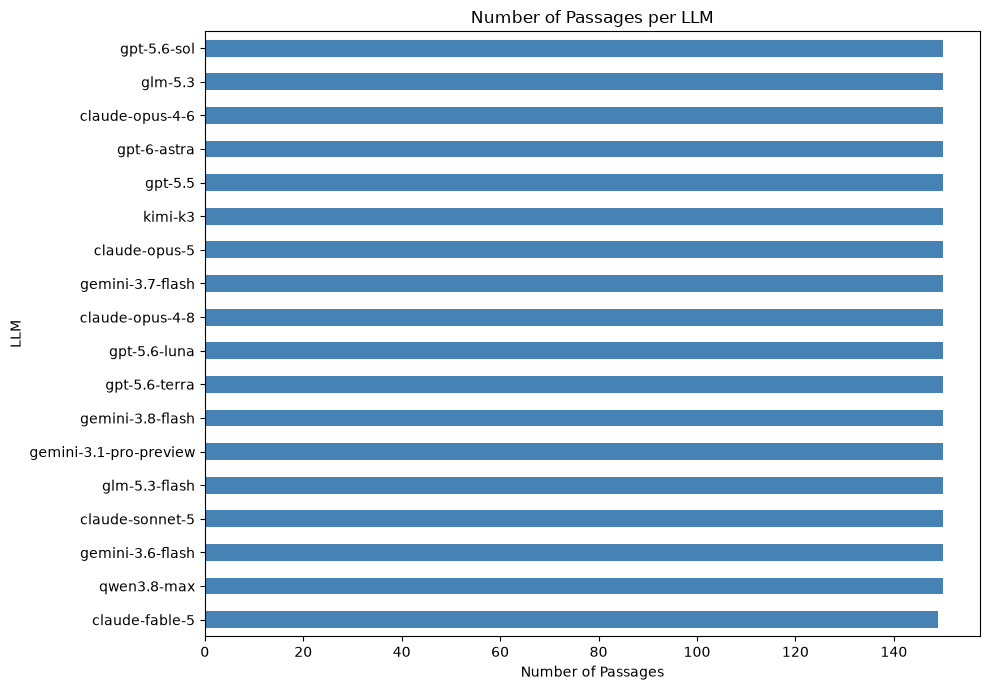

In [4]:
import matplotlib.pyplot as plt

model_counts = df["model"].value_counts().sort_values()

model_counts.plot(kind="barh", figsize=(10, 7), color="steelblue")

plt.title("Number of Passages per LLM")
plt.xlabel("Number of Passages")
plt.ylabel("LLM")
plt.tight_layout()
plt.show()

Passage length statistics:
count    2699.000000
mean      114.659504
std        58.281372
min        36.000000
25%        64.000000
50%       101.000000
75%       157.000000
max       274.000000
Name: word_count, dtype: float64


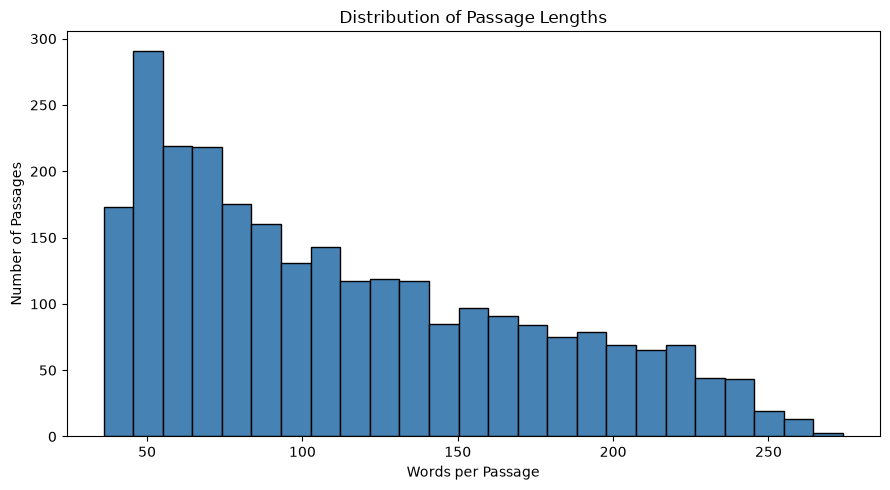

In [5]:
# Count the words in each passage
df["word_count"] = df["text"].str.split().str.len()

print("Passage length statistics:")
print(df["word_count"].describe())

# Show the distribution of passage lengths
plt.figure(figsize=(9, 5))
plt.hist(df["word_count"], bins=25, color="steelblue", edgecolor="black")

plt.title("Distribution of Passage Lengths")
plt.xlabel("Words per Passage")
plt.ylabel("Number of Passages")
plt.tight_layout()
plt.show()

The passages from the dataset range from 36 to 274 words, with an average of about 115 words. The median is 101 words, and the middle 50% fall between 64 and 157 words. Shorter passages are more common than longer ones.

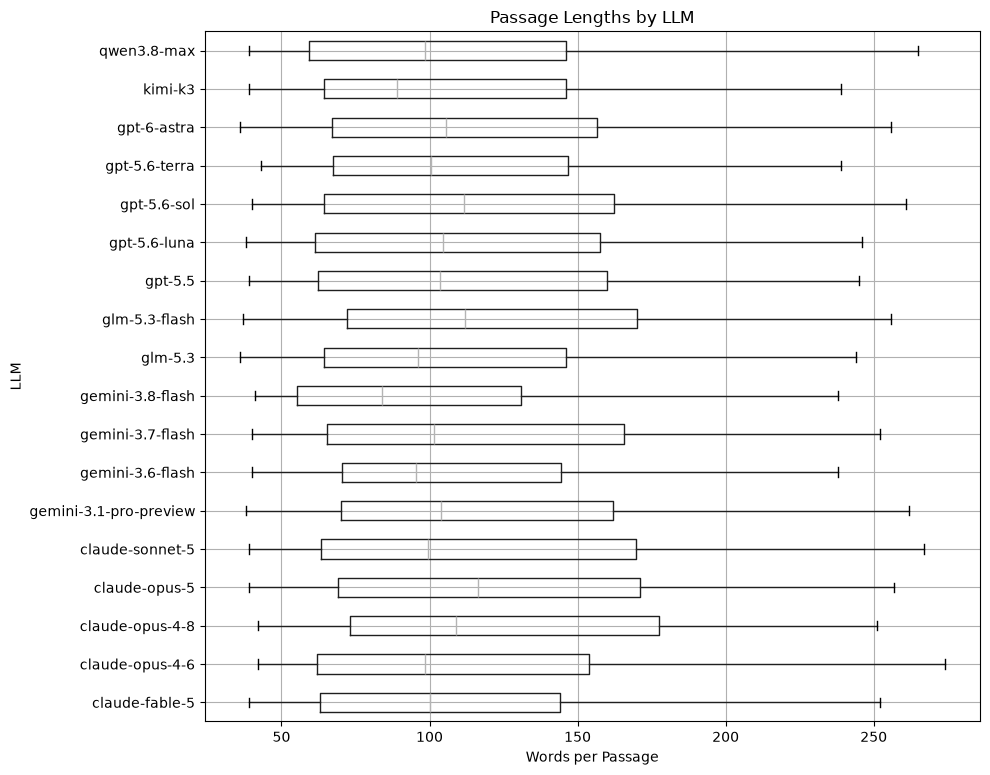

In [6]:
df.boxplot(
    column="word_count",
    by="model",
    vert=False,
    figsize=(10, 8)
)

plt.title("Passage Lengths by LLM")
plt.suptitle("")
plt.xlabel("Words per Passage")
plt.ylabel("LLM")
plt.tight_layout()
plt.show()

In [7]:
# Display the two shortest and two longest passages
columns = ["model", "word_count", "text"]

with pd.option_context("display.max_colwidth", None):
    print("Shortest passages:")
    display(df.nsmallest(2, "word_count")[columns])

    print("Longest passages:")
    display(df.nlargest(2, "word_count")[columns])

Shortest passages:


,model,word_count,text
1436,gpt-6-astra,36,"Data science communities connect people who share knowledge, solve problems, and learn from diverse perspectives. They foster collaboration, encourage ethical practices, and make tools more accessible, helping both newcomers and experts turn data into real-world impact."
2511,glm-5.3,36,"Beneath crushing darkness, life learned to weave light—jellyfish pulsing sapphire, anglerfish dangling false moons. Why countless species independently conjured this cold chemistry remains evolution's riddle, yet in that black cathedral, glowing silence answers with unbearable beauty."


Longest passages:


,model,word_count,text
2329,claude-opus-4-6,274,"The audience can see the letter on the table — they have watched Lady Harwick place it there with trembling, deliberate hands, the letter that confesses everything, that names her lover, that begs forgiveness in language so raw it will unmake a marriage of twenty years — and now they hear Edmund's boots in the corridor, his cheerful whistling, the sound of a man who believes he is coming home to an ordinary evening of wine and familiar silence. He pauses at the doorway to remove his coat. He comments on the rain. He crosses to the fire and warms his palms, standing with his back to the table, inches from the pale envelope, and the audience holds its collective breath like a single organism gripping the armrests of five hundred seats, because they know what he does not: that the moment he turns, the moment his idle gaze falls upon that cream-colored rectangle propped against the candlestick, his understanding of every tender word his wife has spoken for three years will curdle into ash. He is talking now about the garden, about the roses he intends to plant in spring, about how he imagines the two of them growing old among flowers, and every sweet domestic detail is a nail driven deeper into the coffin of his innocence. The audience wants to scream. They want to rush the stage, seize the letter, feed it to the fire before his eyes find it. But theater is the cruelest contract: they must sit, and watch, and know, while Edmund — dear, doomed, whistling Edmund — finally turns toward the table and reaches for the light."
1280,claude-sonnet-5,267,"Beneath the sun-scorched hills of southeastern Anatolia, where the Tigris and Euphrates trace their ancient courses toward Mesopotamia, lies a monument that unravels the tidy narrative of human origins: Göbekli Tepe, raised some eleven and a half millennia ago by hands that had never sown a seed nor fired a pot. Here, hunter-gatherers—bands presumed too primitive for grand ambition—dragged and hewed limestone pillars weighing many tons, arranging them into concentric rings whose T-shaped megaliths loom like watchful ancestors or forgotten gods. Across their surfaces creep a menagerie of the wild: foxes crouch mid-stride, boars bare their tusks, serpents coil in endless knots, scorpions scuttle beside cranes and vultures whose wings seem poised for flight. These are not the tame beasts of pasture but the untamed terrors and totems of a world still ruled by instinct and myth, rendered with a sculptural sophistication that defies the era's supposed simplicity. No hearths, no houses, no granaries mark this place as domestic; it was a sanctuary, perhaps a necropolis of the spirit, where scattered peoples converged from distant valleys to feast, to labor collectively, and to commune with forces beyond survival. That such coordination—the quarrying, the transport, the carving—preceded the plow and the potter's wheel suggests that ritual, not agriculture, may have first drawn scattered humanity into settled cooperation, that belief itself laid the cornerstone of civilization. Buried deliberately beneath tons of backfilled rubble millennia after its raising, as though intentionally returned to earth, Göbekli Tepe endures as a silent, stone-carved testament to a spiritual awakening older than the hearth, older than the harvest, older than history's first recorded word."


I wanted to look at some of the passages to check for data problems or incomplete responses, so I took the 2 longest and shortest passages to check and everything checked out. The lengths alone aren't a reason to remove as they can help with predictablility.

## 4. Training Validation and Test Splits

In [8]:
from sklearn.model_selection import train_test_split

# Assign 70% of the prompts to training
prompt_ids = df["prompt_id"].drop_duplicates().to_numpy()

train_prompts, remaining_prompts = train_test_split(
    prompt_ids,
    test_size=0.30,
    random_state=42
)

# Divide the remaining prompts between validation and testing
val_prompts, test_prompts = train_test_split(
    remaining_prompts,
    test_size=0.50,
    random_state=42
)

# Collect the passages belonging to each group
train_df = df[df["prompt_id"].isin(train_prompts)].copy()
val_df = df[df["prompt_id"].isin(val_prompts)].copy()
test_df = df[df["prompt_id"].isin(test_prompts)].copy()

# Verify that no prompt appears in multiple sets
assert set(train_prompts).isdisjoint(val_prompts)
assert set(train_prompts).isdisjoint(test_prompts)
assert set(val_prompts).isdisjoint(test_prompts)

# Show the size and class coverage of each set
for name, split in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        f"{name}: {len(split)} passages, "
        f"{split['prompt_id'].nunique()} prompts, "
        f"{split['model'].nunique()} LLMs"
    )

print("\nNo prompt overlap between sets.")

Training: 1890 passages, 105 prompts, 18 LLMs
Validation: 396 passages, 22 prompts, 18 LLMs
Test: 413 passages, 23 prompts, 18 LLMs

No prompt overlap between sets.


We split the data by prompt ID into approximately 70% training, 15% validation, and 15% testing. Each set contains all 18 LLMs, and no prompt appears in more than one set. This lets us evaluate performance on responses to unseen prompts.

## 5. Text Features and Preprocessing

In [9]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(train_df["model"].to_numpy())
y_val = label_encoder.transform(val_df["model"].to_numpy())
y_test = label_encoder.transform(test_df["model"].to_numpy())

# Show which number represents each LLM
label_mapping = pd.DataFrame({
    "LLM": label_encoder.classes_,
    "Numeric Label": range(len(label_encoder.classes_))
})

display(label_mapping)

,LLM,Numeric Label
0,claude-fable-5,0
1,claude-opus-4-6,1
2,claude-opus-4-8,2
3,claude-opus-5,3
4,claude-sonnet-5,4
5,gemini-3.1-pro-preview,5
6,gemini-3.6-flash,6
7,gemini-3.7-flash,7
8,gemini-3.8-flash,8
9,glm-5.3,9


In [10]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion

tfidf = FeatureUnion([
    ("word", TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=5000,
        min_df=2,
        dtype=np.float32
    )),
    ("character", TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        max_features=10000,
        min_df=2,
        dtype=np.float32
    ))
])

# Learn the vocabulary and TF-IDF weights from training passages only
X_train_tfidf = tfidf.fit_transform(train_df["text"].to_numpy())

# Apply those same features and weights to validation and test passages
X_val_tfidf = tfidf.transform(val_df["text"].to_numpy())
X_test_tfidf = tfidf.transform(test_df["text"].to_numpy())

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Test TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (1890, 15000)
Validation TF-IDF shape: (396, 15000)
Test TF-IDF shape: (413, 15000)


In [11]:
import re

def get_style_features(text):
    word_count = len(text.split())

    # Estimate sentences using periods, question marks, and exclamation marks
    sentences = [
        sentence for sentence in re.split(r"[.!?]+", text)
        if sentence.strip()
    ]
    sentence_count = max(len(sentences), 1)

    return {
        "word_count": word_count,
        "avg_sentence_words": word_count / sentence_count,
        "commas_per_100_words": text.count(",") / word_count * 100,
        "colons_per_100_words": text.count(":") / word_count * 100,
        "dashes_per_100_words": (
            sum(text.count(dash) for dash in ["-", "–", "—"])
            / word_count * 100
        )
    }

# Calculate the same five measurements for each set
style_train = pd.DataFrame(
    [get_style_features(text) for text in train_df["text"]]
)

style_val = pd.DataFrame(
    [get_style_features(text) for text in val_df["text"]]
)

style_test = pd.DataFrame(
    [get_style_features(text) for text in test_df["text"]]
)

display(style_train.head())
print("Training style features:", style_train.shape)

,word_count,avg_sentence_words,commas_per_100_words,colons_per_100_words,dashes_per_100_words
0,192,24.000000,8.854167,0.520833,0.000000
1,65,16.250000,7.692308,0.000000,3.076923
2,77,19.250000,10.389610,0.000000,0.000000
3,220,24.444444,14.545455,0.454545,0.909091
4,97,24.250000,8.247423,1.030928,2.061856


Training style features: (1890, 5)


In [12]:
from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack

# Learn scaling values from training data only
style_scaler = StandardScaler()

X_train_style = style_scaler.fit_transform(style_train).astype(np.float32)
X_val_style = style_scaler.transform(style_val).astype(np.float32)
X_test_style = style_scaler.transform(style_test).astype(np.float32)

# Combine all 15,000 TF-IDF features with the five style features
X_train_all = hstack(
    [X_train_tfidf, X_train_style], format="csr", dtype=np.float32
)

X_val_all = hstack(
    [X_val_tfidf, X_val_style], format="csr", dtype=np.float32
)

X_test_all = hstack(
    [X_test_tfidf, X_test_style], format="csr", dtype=np.float32
)

print("Training — all features:", X_train_all.shape)
print("Validation — all features:", X_val_all.shape)
print("Test — all features:", X_test_all.shape)

Training — all features: (1890, 15005)
Validation — all features: (396, 15005)
Test — all features: (413, 15005)


## 6. Feature Selection

In [13]:
from sklearn.feature_selection import SelectKBest, chi2

# Rank and select TF-IDF features using training data only
selector = SelectKBest(score_func=chi2, k=5000)

X_train_tfidf_selected = selector.fit_transform(X_train_tfidf, y_train)
X_val_tfidf_selected = selector.transform(X_val_tfidf)
X_test_tfidf_selected = selector.transform(X_test_tfidf)

# Add the same five scaled style features
X_train_selected = hstack(
    [X_train_tfidf_selected, X_train_style],
    format="csr", dtype=np.float32
)

X_val_selected = hstack(
    [X_val_tfidf_selected, X_val_style],
    format="csr", dtype=np.float32
)

X_test_selected = hstack(
    [X_test_tfidf_selected, X_test_style],
    format="csr", dtype=np.float32
)

print("Training — selected features:", X_train_selected.shape)
print("Validation — selected features:", X_val_selected.shape)
print("Test — selected features:", X_test_selected.shape)

Training — selected features: (1890, 5005)
Validation — selected features: (396, 5005)
Test — selected features: (413, 5005)


In [14]:
feature_scores = pd.DataFrame({
    "Feature": tfidf.get_feature_names_out(),
    "Chi-square Score": selector.scores_,
    "Selected": selector.get_support()
})

# Show the ten highest-scoring selected features
top_features = (
    feature_scores[feature_scores["Selected"]]
    .nlargest(10, "Chi-square Score")
)

display(top_features[["Feature", "Chi-square Score"]])

,Feature,Chi-square Score
6381,character__ —,19.056297
148,word__an,13.668658
3197,word__profound,13.641215
6382,character__'s,13.348233
14999,character__’s,11.424992
1838,word__he,11.214013
1416,word__expanse,11.185842
2233,word__known as,10.953022
471,word__biological,10.534991
4291,word__the ultimate,9.877211


We used chi-square feature selection to reduce the TF-IDF features from 15,000 to 5,000. We kept the same five writing-style measurements, giving us 5,005 total features. Selection used only training data. We will compare this initial feature count with the full feature set during model evaluation.

## 7. Logistic Regression

Logistic regression learns one set of feature weights for each LLM and predicts the LLM with the highest score. `C` is the inverse of the L2 penalty, so a larger `C` fits the training passages more closely. Both feature sets are scored on the training and validation passages. The test prompts stay unused until the model comparison.

Chance accuracy: 0.056


,Features,C,Training accuracy,Validation accuracy
0,"Selected (5,005)",0.01,0.206,0.194
1,"Selected (5,005)",0.10,0.271,0.210
2,"Selected (5,005)",1.00,0.681,0.283
3,"Selected (5,005)",3.00,0.941,0.290
4,"Selected (5,005)",10.00,0.999,0.285
5,"All (15,005)",0.01,0.220,0.199
6,"All (15,005)",0.10,0.337,0.212
7,"All (15,005)",1.00,0.877,0.301
8,"All (15,005)",3.00,0.996,0.321
9,"All (15,005)",10.00,1.000,0.316


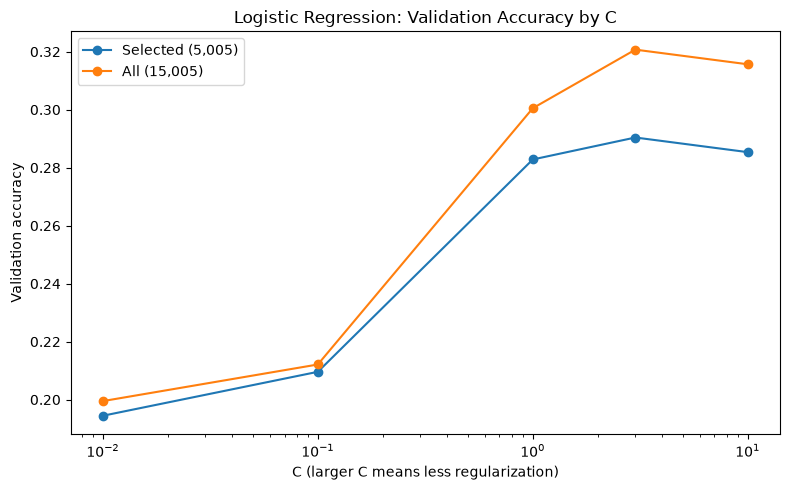

Chosen logistic regression: All (15,005) with C = 3.0
Training accuracy: 0.996 | Validation accuracy: 0.321


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Chance accuracy if every passage were assigned to one of the 18 LLMs at random
print("Chance accuracy:", round(1 / len(label_encoder.classes_), 3))

# C is the inverse of the L2 penalty. A larger C fits the training passages more closely.
# The test prompts stay unused until the final comparison.
C_values = [0.01, 0.1, 1, 3, 10]

logreg_matrices = {
    "Selected (5,005)": (X_train_selected, X_val_selected, X_test_selected),
    "All (15,005)": (X_train_all, X_val_all, X_test_all),
}

logreg_rows = []

for feature_name, (X_tr, X_va, X_te) in logreg_matrices.items():
    for C in C_values:
        model = LogisticRegression(
            C=C,
            solver="lbfgs",
            max_iter=800,
            random_state=42,
        )
        model.fit(X_tr, y_train)

        logreg_rows.append({
            "Features": feature_name,
            "C": C,
            "Training accuracy": accuracy_score(y_train, model.predict(X_tr)),
            "Validation accuracy": accuracy_score(y_val, model.predict(X_va)),
        })

logreg_results = pd.DataFrame(logreg_rows)
display(logreg_results.round(3))

plt.figure(figsize=(8, 5))

for feature_name, group in logreg_results.groupby("Features", sort=False):
    plt.plot(
        group["C"],
        group["Validation accuracy"],
        marker="o",
        label=feature_name,
    )

plt.xscale("log")
plt.xlabel("C (larger C means less regularization)")
plt.ylabel("Validation accuracy")
plt.title("Logistic Regression: Validation Accuracy by C")
plt.legend()
plt.tight_layout()
plt.show()

# If two settings tie on validation accuracy, keep the lower training accuracy.
best_logreg = (
    logreg_results
    .sort_values(["Validation accuracy", "Training accuracy"], ascending=[False, True])
    .iloc[0]
)

logreg_X_train, logreg_X_val, logreg_X_test = logreg_matrices[best_logreg["Features"]]

logreg_model = LogisticRegression(
    C=best_logreg["C"],
    solver="lbfgs",
    max_iter=800,
    random_state=42,
)
logreg_model.fit(logreg_X_train, y_train)

print(
    "Chosen logistic regression:",
    best_logreg["Features"],
    "with C =",
    best_logreg["C"],
)
print(
    "Training accuracy:",
    round(best_logreg["Training accuracy"], 3),
    "| Validation accuracy:",
    round(best_logreg["Validation accuracy"], 3),
)

The best validation accuracy is 0.321, from the full 15,005 features with C = 3. That is well above the 0.056 chance level. Training accuracy at that setting is 0.996, so the model still memorizes most of the training passages. Smaller values of C shrink that gap, but validation accuracy drops with them. The 5,005 selected features stay a little below the full set at every C we tried. We keep the full feature set and C = 3.

## 8. Linear Support Vector Machine

A linear support vector machine also learns one weight vector per LLM, but it places the boundary to maximize the margin between classes. `LinearSVC` trains a separate binary classifier for each LLM. There are more features than training passages, so we use the dual formulation. We tune `C` on the same two feature sets and again leave the test prompts untouched.

,Features,C,Training accuracy,Validation accuracy
0,"Selected (5,005)",0.01,0.354,0.207
1,"Selected (5,005)",0.10,0.907,0.283
2,"Selected (5,005)",0.30,0.994,0.306
3,"Selected (5,005)",1.00,1.000,0.285
4,"Selected (5,005)",3.00,1.000,0.275
5,"All (15,005)",0.01,0.511,0.227
6,"All (15,005)",0.10,0.990,0.311
7,"All (15,005)",0.30,1.000,0.318
8,"All (15,005)",1.00,1.000,0.295
9,"All (15,005)",3.00,1.000,0.283


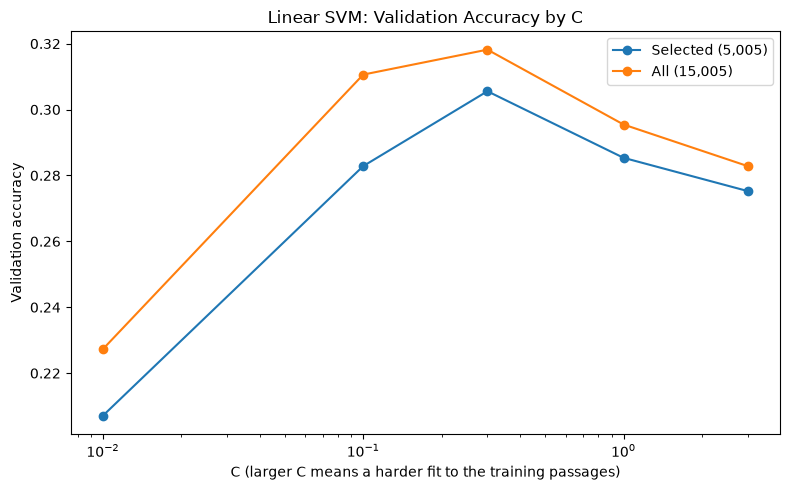

Chosen linear SVM: All (15,005) with C = 0.3
Training accuracy: 1.0 | Validation accuracy: 0.318


In [16]:
from sklearn.svm import LinearSVC

# C controls the penalty on points that fall inside the margin.
C_values = [0.01, 0.1, 0.3, 1, 3]

svm_matrices = {
    "Selected (5,005)": (X_train_selected, X_val_selected, X_test_selected),
    "All (15,005)": (X_train_all, X_val_all, X_test_all),
}

svm_rows = []

for feature_name, (X_tr, X_va, X_te) in svm_matrices.items():
    for C in C_values:
        model = LinearSVC(
            C=C,
            dual=True,
            max_iter=4000,
            random_state=42,
        )
        model.fit(X_tr, y_train)

        svm_rows.append({
            "Features": feature_name,
            "C": C,
            "Training accuracy": accuracy_score(y_train, model.predict(X_tr)),
            "Validation accuracy": accuracy_score(y_val, model.predict(X_va)),
        })

svm_results = pd.DataFrame(svm_rows)
display(svm_results.round(3))

plt.figure(figsize=(8, 5))

for feature_name, group in svm_results.groupby("Features", sort=False):
    plt.plot(
        group["C"],
        group["Validation accuracy"],
        marker="o",
        label=feature_name,
    )

plt.xscale("log")
plt.xlabel("C (larger C means a harder fit to the training passages)")
plt.ylabel("Validation accuracy")
plt.title("Linear SVM: Validation Accuracy by C")
plt.legend()
plt.tight_layout()
plt.show()

best_svm = (
    svm_results
    .sort_values(["Validation accuracy", "Training accuracy"], ascending=[False, True])
    .iloc[0]
)

svm_X_train, svm_X_val, svm_X_test = svm_matrices[best_svm["Features"]]

svm_model = LinearSVC(
    C=best_svm["C"],
    dual=True,
    max_iter=4000,
    random_state=42,
)
svm_model.fit(svm_X_train, y_train)

print(
    "Chosen linear SVM:",
    best_svm["Features"],
    "with C =",
    best_svm["C"],
)
print(
    "Training accuracy:",
    round(best_svm["Training accuracy"], 3),
    "| Validation accuracy:",
    round(best_svm["Validation accuracy"], 3),
)

The best validation accuracy is 0.318, from the full 15,005 features with C = 0.3. That is almost the same as logistic regression. Training accuracy is 1.000, so the margin is fit tightly to the training passages. Larger values of C do not improve the validation set, and the reduced feature set stays slightly behind the full set. We keep the full 15,005 features and C = 0.3.

## 9. MLP Development and Training

The multilayer perceptron adds a hidden layer with ReLU activations, so it can combine word, character, and style features instead of treating each one on its own. The training set has 1,890 passages and thousands of features, so a large network can memorize the training text. We start with one hidden layer of 64 units, then try a wider layer, stronger L2 regularization (`alpha`), and one two-layer network.

Adam's learning rate stays at 0.001, and each update uses a mini-batch of 64 passages. sklearn can stop training with its own validation split, but that split is random rows and can put two answers to the same prompt on opposite sides. We train one epoch at a time and keep the epoch with the best accuracy on the prompt-level validation set. Architectures are compared on the 5,005 selected features, and the winner is then trained again on the full feature set.

In [17]:
import copy
import warnings

from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPClassifier

# The MLP trains on dense arrays, so convert each feature matrix once.
mlp_matrices = {
    "Selected (5,005)": (
        X_train_selected.toarray(),
        X_val_selected.toarray(),
        X_test_selected.toarray(),
    ),
    "All (15,005)": (
        X_train_all.toarray(),
        X_val_all.toarray(),
        X_test_all.toarray(),
    ),
}

def train_mlp(X_train, y_train, X_val, y_val, hidden_layer_sizes, alpha, max_epochs=30):
    mlp = MLPClassifier(
        hidden_layer_sizes=hidden_layer_sizes,
        activation="relu",
        solver="adam",
        alpha=alpha,
        batch_size=64,
        learning_rate_init=0.001,
        max_iter=1,
        warm_start=True,
        random_state=42,
        tol=0,
    )

    history = []
    best_model = None
    best_val = -1

    for epoch in range(1, max_epochs + 1):
        # max_iter is 1 on purpose, so ignore the warning that training has not converged yet.
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            mlp.fit(X_train, y_train)

        train_acc = accuracy_score(y_train, mlp.predict(X_train))
        val_acc = accuracy_score(y_val, mlp.predict(X_val))

        history.append({
            "Epoch": epoch,
            "Training loss": float(mlp.loss_),
            "Training accuracy": train_acc,
            "Validation accuracy": val_acc,
        })

        if val_acc > best_val:
            best_val = val_acc
            best_model = copy.deepcopy(mlp)

    return best_model, pd.DataFrame(history)

mlp_configs = [
    ((64,), 0.0001),
    ((128,), 0.0001),
    ((128,), 0.001),
    ((128,), 0.01),
    ((256,), 0.001),
    ((128, 64), 0.001),
]

X_tr, X_va, X_te = mlp_matrices["Selected (5,005)"]
mlp_runs = []

for hidden_layer_sizes, alpha in mlp_configs:
    model, history = train_mlp(
        X_tr, y_train, X_va, y_val, hidden_layer_sizes, alpha
    )
    best = history.loc[history["Validation accuracy"].idxmax()]

    mlp_runs.append({
        "Features": "Selected (5,005)",
        "Hidden layers": hidden_layer_sizes,
        "Alpha": alpha,
        "Best epoch": int(best["Epoch"]),
        "Training accuracy": best["Training accuracy"],
        "Validation accuracy": best["Validation accuracy"],
        "model": model,
        "history": history,
    })

mlp_search = pd.DataFrame([
    {
        "Hidden layers": ", ".join(str(size) for size in run["Hidden layers"]),
        "Alpha": run["Alpha"],
        "Best epoch": run["Best epoch"],
        "Training accuracy": round(run["Training accuracy"], 3),
        "Validation accuracy": round(run["Validation accuracy"], 3),
    }
    for run in mlp_runs
])

display(mlp_search)

,Hidden layers,Alpha,Best epoch,Training accuracy,Validation accuracy
0,64,0.0001,15,0.849,0.306
1,128,0.0001,26,0.979,0.328
2,128,0.0010,24,0.968,0.333
3,128,0.0100,19,0.929,0.326
4,256,0.0010,14,0.957,0.321
5,"128, 64",0.0010,13,0.925,0.295


,Features,Hidden layers,Alpha,Best epoch,Training accuracy,Validation accuracy
0,"Selected (5,005)",128,0.001,24,0.968,0.333
1,"All (15,005)",128,0.001,23,0.992,0.323


Chosen MLP: Selected (5,005) | hidden layers = (128,) | alpha = 0.001 | epoch = 24
Training accuracy: 0.968 | Validation accuracy: 0.333


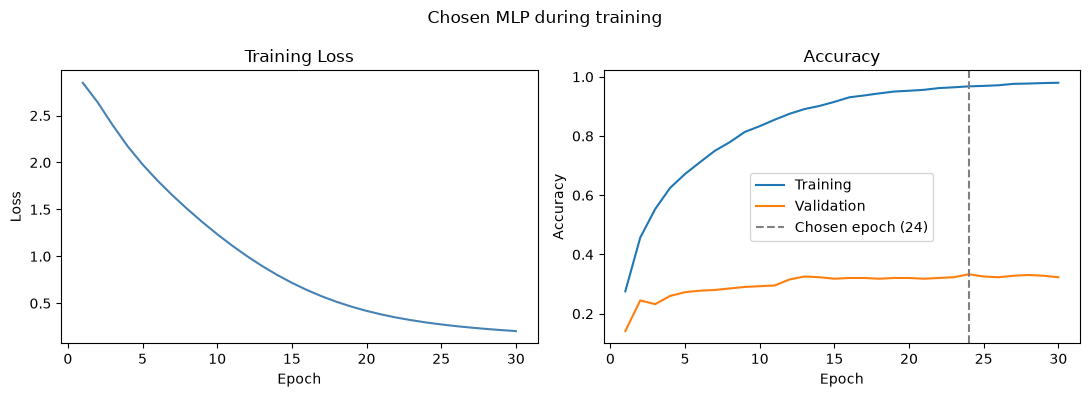

In [18]:
# Keep the selected-feature run with the best validation accuracy.
# If two runs tie, keep the one with the lower training accuracy.
best_run = sorted(
    mlp_runs,
    key=lambda run: (run["Validation accuracy"], -run["Training accuracy"]),
    reverse=True,
)[0]

# Train that same architecture on the full feature set.
X_tr, X_va, X_te = mlp_matrices["All (15,005)"]
model_all, history_all = train_mlp(
    X_tr,
    y_train,
    X_va,
    y_val,
    best_run["Hidden layers"],
    best_run["Alpha"],
)
best_all = history_all.loc[history_all["Validation accuracy"].idxmax()]

mlp_comparison = pd.DataFrame([
    {
        "Features": "Selected (5,005)",
        "Hidden layers": ", ".join(str(size) for size in best_run["Hidden layers"]),
        "Alpha": best_run["Alpha"],
        "Best epoch": best_run["Best epoch"],
        "Training accuracy": round(best_run["Training accuracy"], 3),
        "Validation accuracy": round(best_run["Validation accuracy"], 3),
    },
    {
        "Features": "All (15,005)",
        "Hidden layers": ", ".join(str(size) for size in best_run["Hidden layers"]),
        "Alpha": best_run["Alpha"],
        "Best epoch": int(best_all["Epoch"]),
        "Training accuracy": round(best_all["Training accuracy"], 3),
        "Validation accuracy": round(best_all["Validation accuracy"], 3),
    },
])

display(mlp_comparison)

if best_all["Validation accuracy"] > best_run["Validation accuracy"]:
    chosen_name = "All (15,005)"
    mlp_model = model_all
    mlp_history = history_all
else:
    chosen_name = "Selected (5,005)"
    mlp_model = best_run["model"]
    mlp_history = best_run["history"]

mlp_X_train, mlp_X_val, mlp_X_test = mlp_matrices[chosen_name]
chosen_epoch = int(mlp_history.loc[mlp_history["Validation accuracy"].idxmax(), "Epoch"])
chosen_row = mlp_history.loc[mlp_history["Validation accuracy"].idxmax()]

print(
    "Chosen MLP:",
    chosen_name,
    "| hidden layers =",
    best_run["Hidden layers"],
    "| alpha =",
    best_run["Alpha"],
    "| epoch =",
    chosen_epoch,
)
print(
    "Training accuracy:",
    round(chosen_row["Training accuracy"], 3),
    "| Validation accuracy:",
    round(chosen_row["Validation accuracy"], 3),
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(mlp_history["Epoch"], mlp_history["Training loss"], color="steelblue")
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

axes[1].plot(mlp_history["Epoch"], mlp_history["Training accuracy"], label="Training")
axes[1].plot(mlp_history["Epoch"], mlp_history["Validation accuracy"], label="Validation")
axes[1].axvline(
    chosen_epoch,
    color="gray",
    linestyle="--",
    label=f"Chosen epoch ({chosen_epoch})",
)
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

fig.suptitle("Chosen MLP during training")
fig.tight_layout()
plt.show()

On the selected features, one hidden layer of 128 units with alpha = 0.001 reached the highest validation accuracy, 0.333, at epoch 24. Training accuracy at that epoch is 0.968. The loss keeps falling after that point while validation accuracy levels off, so later epochs mostly memorize training passages. A layer of 64 units was too small (0.306). A layer of 256 units and a second hidden layer of 64 units were both worse than the 128-unit layer. Raising alpha to 0.01 only moved validation accuracy to 0.326.

The same 128-unit network trained on all 15,005 features reached 0.323, a little below the selected features. For the linear models the extra features helped, but here they gave the network more training text to memorize. We keep the 5,005 selected features, 128 hidden units, alpha = 0.001, and the weights from epoch 24.

## 10. Model Evaluation and Comparison

Python 3.14.7 | scikit-learn 1.9.1 | numpy 2.5.3 | pandas 3.0.6


,Classifier,Feature set,Accuracy,Macro precision,Macro recall,Macro F1
0,Logistic regression,"All (15,005)",0.339,0.319,0.338,0.318
2,Logistic regression,"Selected (5,005)",0.324,0.303,0.324,0.303
1,Linear SVM,"All (15,005)",0.356,0.334,0.355,0.334
3,Linear SVM,"Selected (5,005)",0.349,0.331,0.348,0.324
4,MLP,"All (15,005)",0.341,0.335,0.341,0.331
5,MLP,"Selected (5,005)",0.339,0.352,0.338,0.332


Logistic regression: accuracy change -0.015, macro F1 change -0.015
Linear SVM: accuracy change -0.007, macro F1 change -0.010
MLP: accuracy change -0.002, macro F1 change +0.001


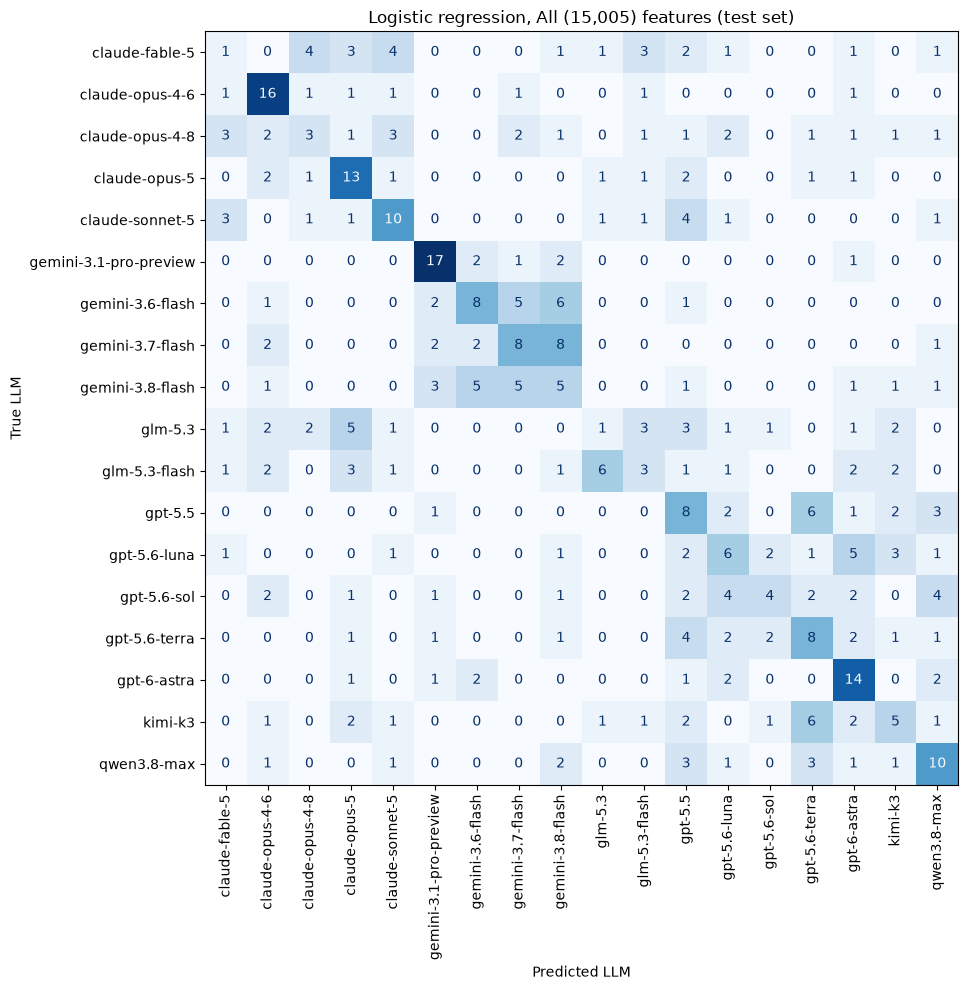

('Logistic regression', 'All (15,005)') top confusions:
   true gemini-3.7-flash -> predicted gemini-3.8-flash: 8
   true kimi-k3 -> predicted gpt-5.6-terra: 6
   true gemini-3.6-flash -> predicted gemini-3.8-flash: 6
   true gpt-5.5 -> predicted gpt-5.6-terra: 6
   true glm-5.3-flash -> predicted glm-5.3: 6


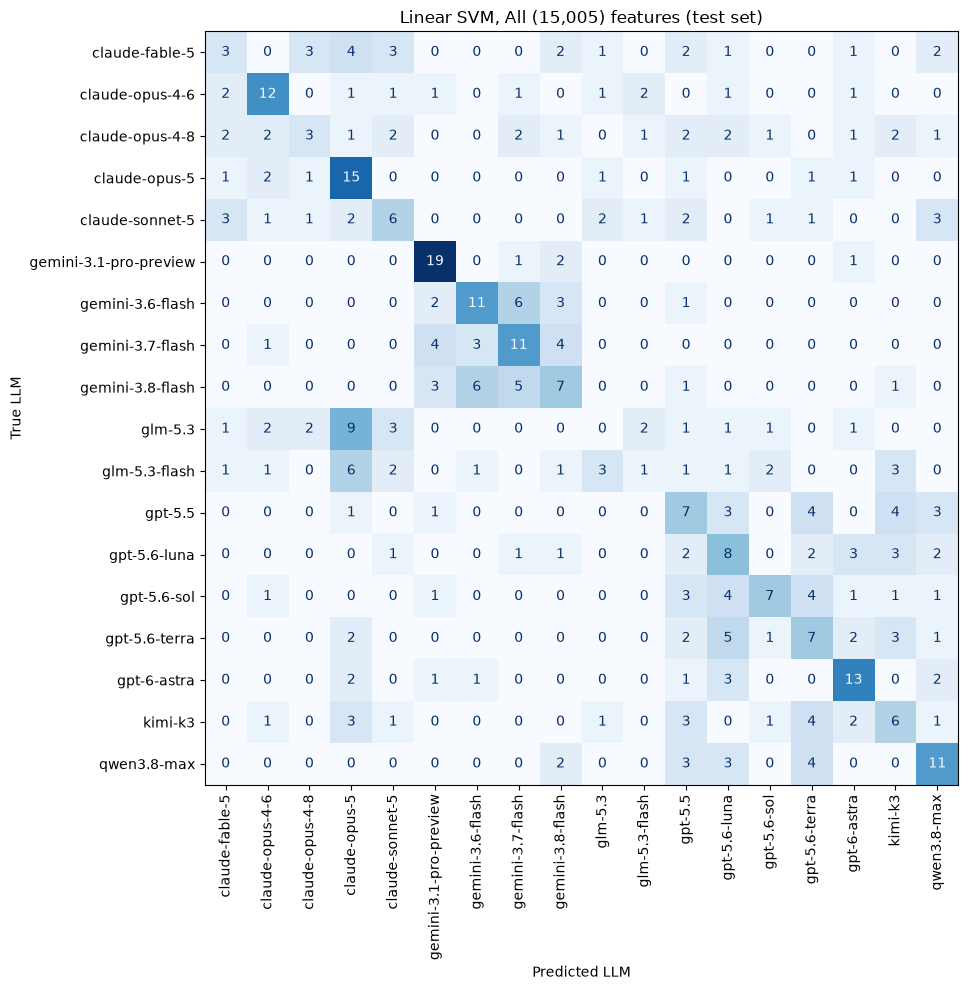

('Linear SVM', 'All (15,005)') top confusions:
   true glm-5.3 -> predicted claude-opus-5: 9
   true gemini-3.8-flash -> predicted gemini-3.6-flash: 6
   true gemini-3.6-flash -> predicted gemini-3.7-flash: 6
   true glm-5.3-flash -> predicted claude-opus-5: 6
   true gpt-5.6-terra -> predicted gpt-5.6-luna: 5


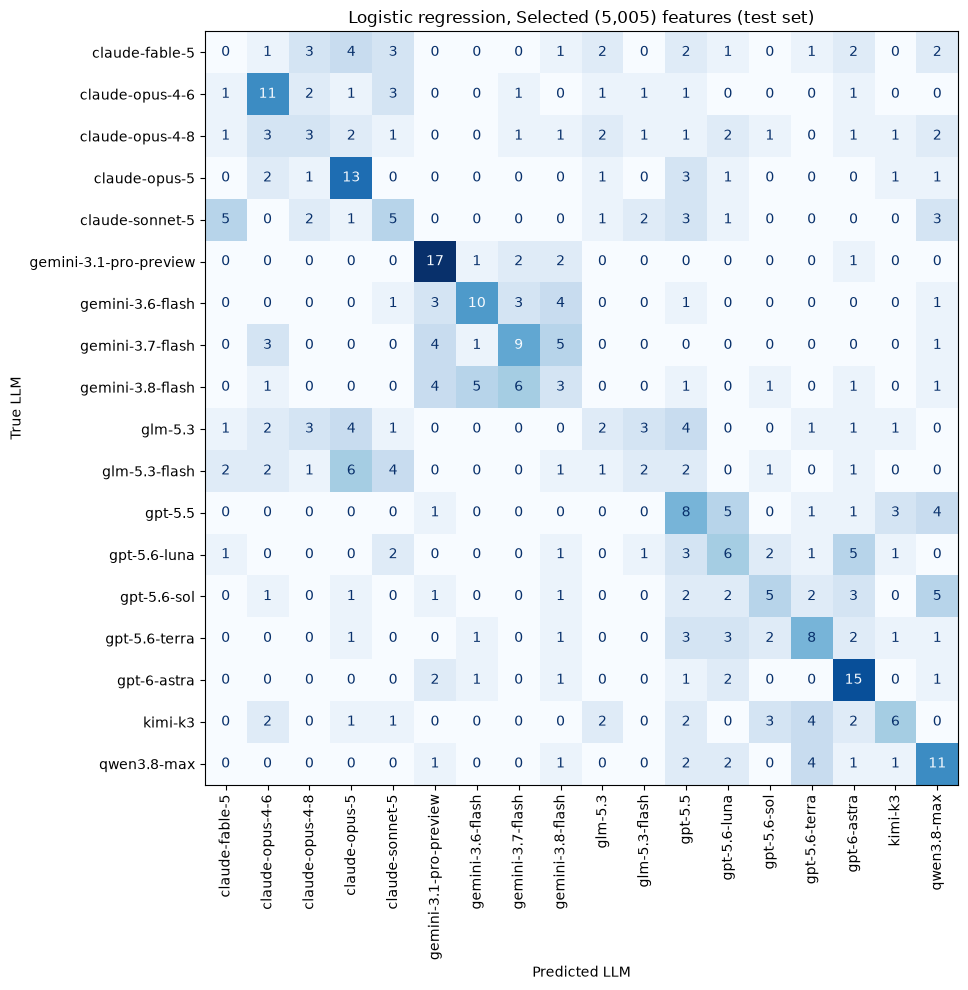

('Logistic regression', 'Selected (5,005)') top confusions:
   true gemini-3.8-flash -> predicted gemini-3.7-flash: 6
   true glm-5.3-flash -> predicted claude-opus-5: 6
   true gemini-3.8-flash -> predicted gemini-3.6-flash: 5
   true gpt-5.6-sol -> predicted qwen3.8-max: 5
   true gemini-3.7-flash -> predicted gemini-3.8-flash: 5


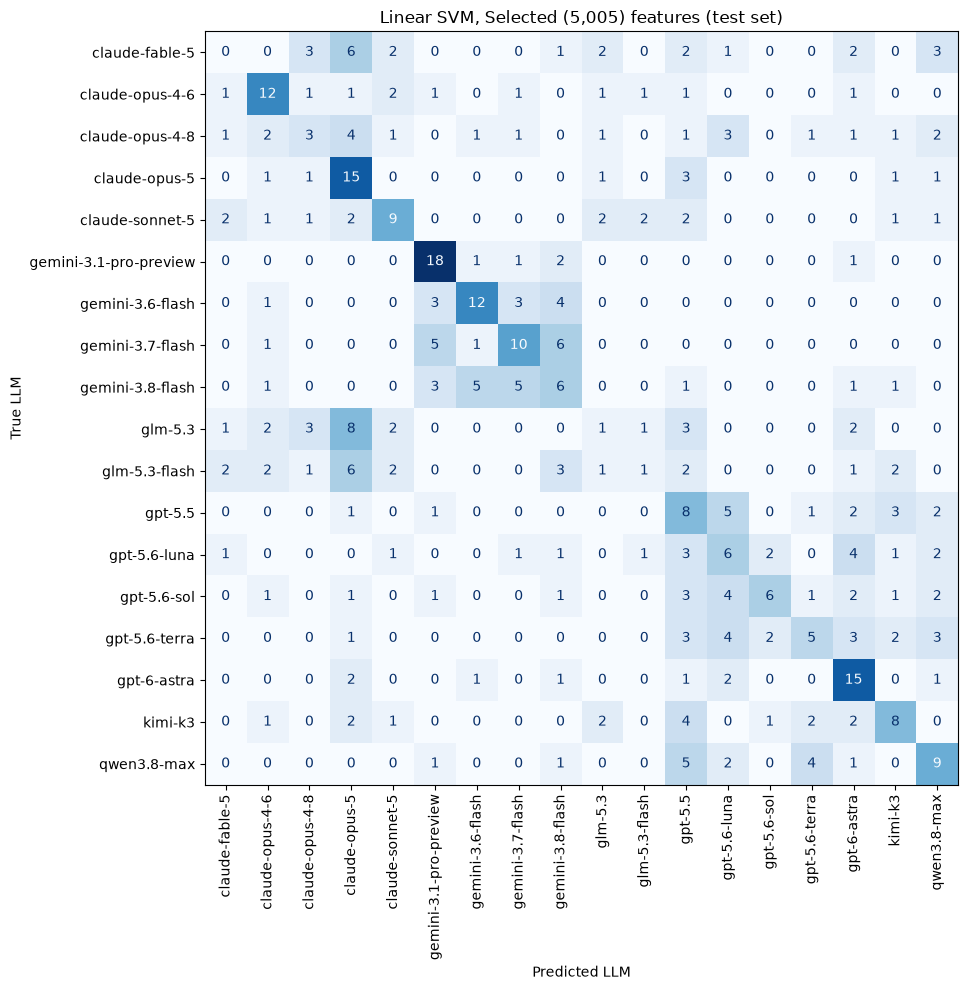

('Linear SVM', 'Selected (5,005)') top confusions:
   true glm-5.3 -> predicted claude-opus-5: 8
   true claude-fable-5 -> predicted claude-opus-5: 6
   true glm-5.3-flash -> predicted claude-opus-5: 6
   true gemini-3.7-flash -> predicted gemini-3.8-flash: 6
   true gemini-3.7-flash -> predicted gemini-3.1-pro-preview: 5


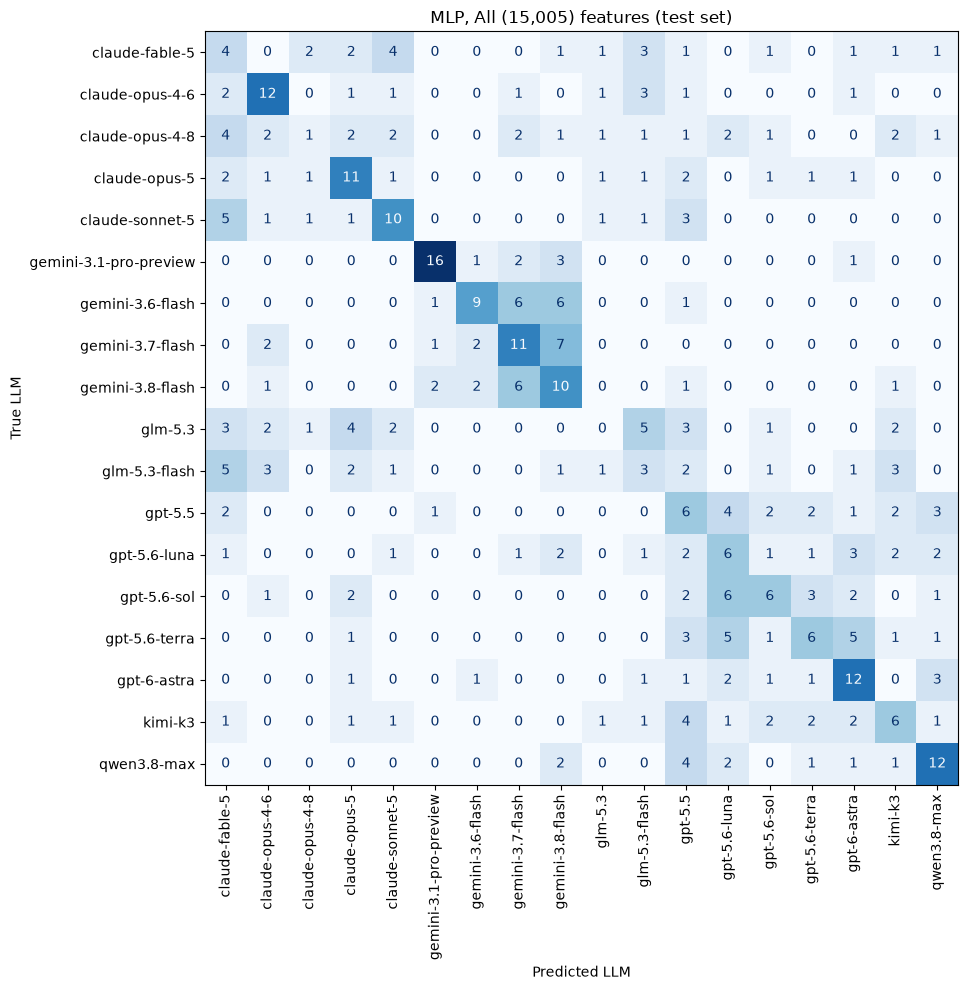

('MLP', 'All (15,005)') top confusions:
   true gemini-3.7-flash -> predicted gemini-3.8-flash: 7
   true gemini-3.8-flash -> predicted gemini-3.7-flash: 6
   true gpt-5.6-sol -> predicted gpt-5.6-luna: 6
   true gemini-3.6-flash -> predicted gemini-3.7-flash: 6
   true gemini-3.6-flash -> predicted gemini-3.8-flash: 6


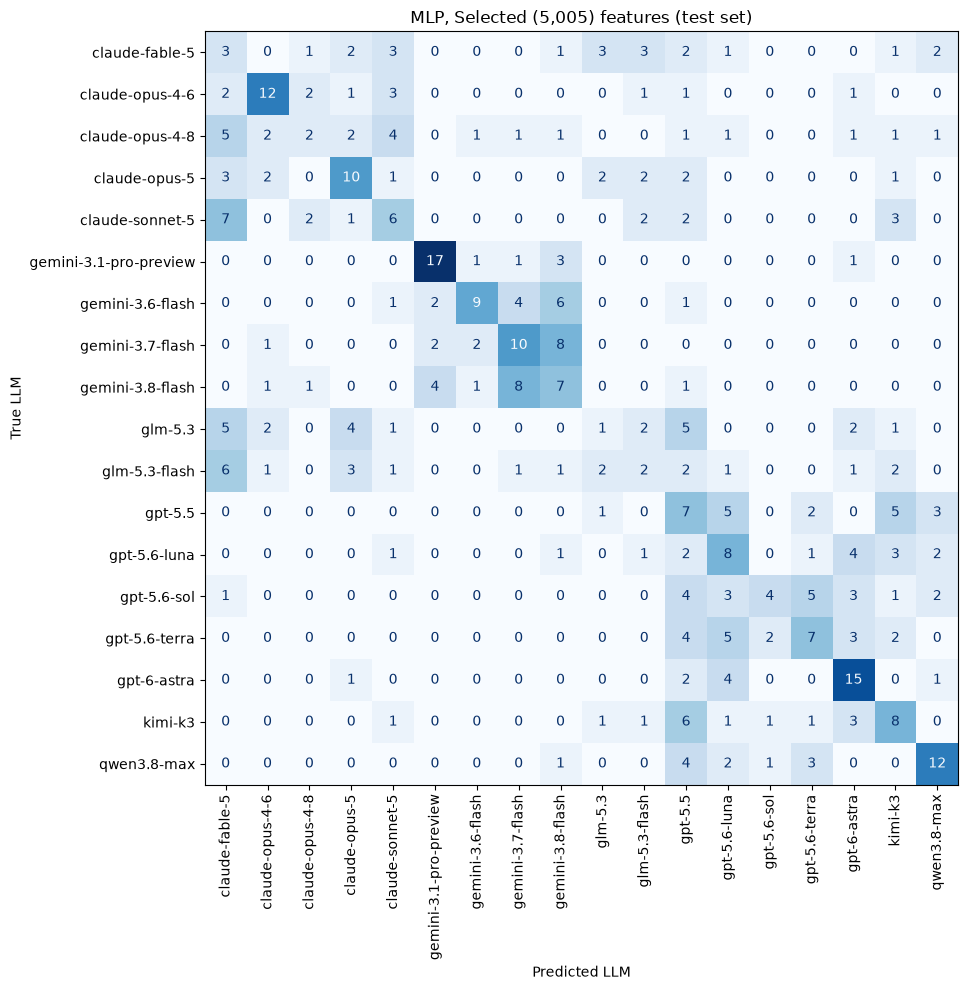

('MLP', 'Selected (5,005)') top confusions:
   true gemini-3.8-flash -> predicted gemini-3.7-flash: 8
   true gemini-3.7-flash -> predicted gemini-3.8-flash: 8
   true claude-sonnet-5 -> predicted claude-fable-5: 7
   true kimi-k3 -> predicted gpt-5.5: 6
   true gemini-3.6-flash -> predicted gemini-3.8-flash: 6


In [19]:
import sys
import sklearn
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay

print("Python", sys.version.split()[0], "| scikit-learn", sklearn.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__)

def best_C(results, feats):
    rows = results[results["Features"] == feats]
    return rows.sort_values(["Validation accuracy", "Training accuracy"],
                            ascending=[False, True]).iloc[0]["C"]

final_models = {}
for feats in ["All (15,005)", "Selected (5,005)"]:
    X_tr, X_va, X_te = logreg_matrices[feats]
    lr = LogisticRegression(C=best_C(logreg_results, feats), solver="lbfgs",
                            max_iter=800, random_state=42).fit(X_tr, y_train)
    svm = LinearSVC(C=best_C(svm_results, feats), dual=True,
                    max_iter=4000, random_state=42).fit(X_tr, y_train)
    final_models[("Logistic regression", feats)] = (lr, X_te)
    final_models[("Linear SVM", feats)] = (svm, X_te)

final_models[("MLP", "All (15,005)")] = (model_all, mlp_matrices["All (15,005)"][2])
final_models[("MLP", "Selected (5,005)")] = (best_run["model"], mlp_matrices["Selected (5,005)"][2])

rows, preds = [], {}
for (name, feats), (model, X_te) in final_models.items():
    pred = model.predict(X_te)
    preds[(name, feats)] = pred
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
    rows.append({"Classifier": name, "Feature set": feats,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Macro precision": p, "Macro recall": r, "Macro F1": f})

test_results = pd.DataFrame(rows)
order = {"Logistic regression": 0, "Linear SVM": 1, "MLP": 2}
test_results = test_results.sort_values(["Classifier", "Feature set"],
                                        key=lambda s: s.map(order) if s.name == "Classifier" else s)
display(test_results.round(3))

# Change from feature selection (Selected minus All) for each model
for name in order:
    a = test_results[(test_results.Classifier == name) & (test_results["Feature set"] == "All (15,005)")].iloc[0]
    s = test_results[(test_results.Classifier == name) & (test_results["Feature set"] == "Selected (5,005)")].iloc[0]
    print(f"{name}: accuracy change {s.Accuracy - a.Accuracy:+.3f}, macro F1 change {s['Macro F1'] - a['Macro F1']:+.3f}")

# Confusion matrices and most common confusions
labels = label_encoder.classes_
for key, pred in preds.items():
    cm = confusion_matrix(y_test, pred, labels=range(len(labels)))
    fig, ax = plt.subplots(figsize=(10, 10))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, xticks_rotation=90,
                                                           colorbar=False, cmap="Blues")
    ax.set_title(f"{key[0]}, {key[1]} features (test set)")
    ax.set_xlabel("Predicted LLM"); ax.set_ylabel("True LLM")
    plt.tight_layout(); plt.show()

    off = cm.copy(); np.fill_diagonal(off, 0)
    top = np.dstack(np.unravel_index(np.argsort(off.ravel())[::-1][:5], off.shape))[0]
    print(key, "top confusions:")
    for t, p_ in top:
        print(f"   true {labels[t]} -> predicted {labels[p_]}: {off[t, p_]}")

## 11. Discussion and Limitations

## 12. Conclusions